#### Notebook 08 — Privacy-Preserving MNO Analytics

This notebook builds on the analytical workflows developed in Notebooks 01–07 and investigates how useful population-level insights can be generated from MNO data while reducing the exposure of sensitive subscriber information.

The focus is on five privacy-related capabilities:
1. Pseudonymisation: Replace direct subscriber identifiers with keyed pseudonymous identifiers.
2. Data minimisation and aggregation: Restrict processing to necessary fields and produce geographic aggregates rather than subscriber-level outputs.
3. Differential privacy: Demonstrate how calibrated statistical noise can protect aggregate subscriber counts and activity statistics.
4. Private Set Intersection (PSI): Explore how two organisations could identify overlapping subscriber records without exchanging their raw identifiers.
5. Secure Multi-Party Computation (MPC) and Homomorphic Encryption (HE): Demonstrate how parties can calculate selected statistics without directly sharing their underlying data.

We'll also create a privacy risk assessment, compare privacy and analytical utility, and produce an operator-facing privacy implementation checklist.

Important distinction: This notebook contains educational demonstrations and prototype safeguards. Pseudonymisation is not anonymisation; minimum-group suppression is not differential privacy; and the simplified PSI/MPC/HE demonstrations are not production-ready cryptographic protocols. A real MNO deployment would require specialist cryptographic review, threat modelling, key management, access controls and a formal privacy assessment.

In [1]:
# CELL 1: IMPORTS AND CONFIGURATION

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import os
import json
import hmac
import hashlib
import secrets
import getpass
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv

print("python-dotenv installed successfully!")

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
NOTEBOOK08_DIR = PROCESSED_DIR / "notebook_08"
REPORTS_DIR = PROJECT_ROOT / "reports"

NOTEBOOK08_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = RAW_DIR / "MPD_sample_synthetic_ken_3000subs_full.csv"

# Privacy configuration
MIN_GROUP_SIZE = 10
MAX_EVENTS_PER_SUBSCRIBER_ZONE = 100

# Differential privacy demonstration parameter.
# This is illustrative, not a recommended production privacy budget.
DP_EPSILON = 1.0

# For subscriber counts, each subscriber contributes at most
# one count to an individual geographic-zone query.
DP_SENSITIVITY = 1.0

GRID_SIZE = 0.05

print("Project root:", PROJECT_ROOT)
print("Input file:", INPUT_FILE)
print("Notebook 08 output:", NOTEBOOK08_DIR)

python-dotenv installed successfully!
Project root: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference
Input file: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/raw/MPD_sample_synthetic_ken_3000subs_full.csv
Notebook 08 output: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_08


#### 2 — Check dependencies and input data

In [2]:
# CELL 2: CHECK INPUT DATA AND OPTIONAL CRYPTOGRAPHIC PACKAGES

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_FILE}\n"
        "Place the synthetic MNO dataset in data/raw/."
    )

print("Input dataset found.")
print(f"Dataset size: {INPUT_FILE.stat().st_size / (1024**2):.2f} MB")

try:
    import phe
    PHE_AVAILABLE = True
    print("Paillier encryption package: available")
except ImportError:
    PHE_AVAILABLE = False
    print("Paillier encryption package: not installed")

print("Python version:", os.sys.version)

Input dataset found.
Dataset size: 133.47 MB
Paillier encryption package: not installed
Python version: 3.11.18 (main, Oct 26 2026, 11:32:31) [Clang 21.1.8 ]


#### 3 — Define data minimisation rules

The first privacy control is to avoid processing fields that are not needed for the intended analytical output.

The pipeline will use only the following fields:
- Subscriber identifier.
- Event timestamp.
- Cell identifier.
- Latitude.
- Longitude.
- Record type, if available.

Simulator-generated labels such as location_target, profile and movement_profile are deliberately excluded.

In [3]:
# CELL 3: DATA MINIMISATION

REQUIRED_COLUMNS = [
    "msisdn",
    "datetime",
    "cell_id",
    "latitude",
    "longitude"
]

OPTIONAL_COLUMNS = [
    "data_type"
]

def minimise_mno_columns(dataframe):

    available_columns = (
        REQUIRED_COLUMNS
        + [
            col for col in OPTIONAL_COLUMNS
            if col in dataframe.columns
        ]
    )

    missing = [
        col for col in REQUIRED_COLUMNS
        if col not in dataframe.columns
    ]

    if missing:
        raise ValueError(
            f"Required columns missing: {missing}"
        )

    return dataframe[available_columns].copy()


sample = pd.read_csv(
    INPUT_FILE,
    nrows=1000,
    low_memory=False
)

minimised_sample = minimise_mno_columns(sample)

print("Original columns:", len(sample.columns))
print("Retained columns:", len(minimised_sample.columns))

display(minimised_sample.head())

Original columns: 16
Retained columns: 6


,msisdn,datetime,cell_id,latitude,longitude,data_type
0,subscribers_00323,2026-02-01 01:23:00,33597,-1.2674,36.9147,CDR
1,subscribers_00323,2026-02-01 03:55:00,33597,-1.2674,36.9147,CDR
2,subscribers_00323,2026-02-01 06:53:00,33597,-1.2674,36.9147,CDR
3,subscribers_00323,2026-02-01 07:52:00,33597,-1.2674,36.9147,CDR
4,subscribers_00323,2026-02-01 09:07:00,31239,-1.2712,36.8996,CDR


#### 4 — Implement keyed pseudonymisation

A plain hash of a subscriber identifier can be vulnerable to dictionary attacks if the identifier space is predictable.

In [4]:
# Load environment variables from the project root.
load_dotenv(PROJECT_ROOT / ".env")

# Retrieve the secret key.
secret_key = os.getenv("MNO_PSEUDONYM_SECRET")

if not secret_key:
    raise ValueError(
        "MNO_PSEUDONYM_SECRET was not found. "
        "Check that your .env file exists and contains the key."
    )

if len(secret_key) < 32:
    raise ValueError(
        "Use a secret key containing at least 32 characters."
    )

SECRET_KEY_BYTES = secret_key.encode("utf-8")


def pseudonymise_identifier(identifier, secret_key):
    """Generate a deterministic HMAC-SHA256 pseudonymous identifier."""

    if pd.isna(identifier):
        return None

    message = str(identifier).encode("utf-8")

    return hmac.new(
        secret_key,
        message,
        hashlib.sha256
    ).hexdigest()


minimised_sample["subscriber_token"] = (
    minimised_sample["msisdn"].apply(
        lambda x: pseudonymise_identifier(
            x,
            SECRET_KEY_BYTES
        )
    )
)

# Remove direct subscriber identifiers.
pseudonymised_sample = minimised_sample.drop(
    columns=["msisdn"]
)

display(
    pseudonymised_sample[
        ["subscriber_token", "datetime", "cell_id"]
    ].head()
)


,subscriber_token,datetime,cell_id
0,c9f4ed5fbc5a1fedb1d0b9a2ec4f81a7b40eba7a418592...,2026-02-01 01:23:00,33597
1,c9f4ed5fbc5a1fedb1d0b9a2ec4f81a7b40eba7a418592...,2026-02-01 03:55:00,33597
2,c9f4ed5fbc5a1fedb1d0b9a2ec4f81a7b40eba7a418592...,2026-02-01 06:53:00,33597
3,c9f4ed5fbc5a1fedb1d0b9a2ec4f81a7b40eba7a418592...,2026-02-01 07:52:00,33597
4,c9f4ed5fbc5a1fedb1d0b9a2ec4f81a7b40eba7a418592...,2026-02-01 09:07:00,31239


#### 5 — Demonstrate the importance of key separation

The same identifier produces different tokens under different keys.

This helps demonstrate why separate projects or data-sharing arrangements should not automatically reuse the same pseudonymisation key.

In [5]:
# CELL 5: KEY SEPARATION DEMONSTRATION

identifier = "SYNTHETIC_SUBSCRIBER_001"

key_a = secrets.token_bytes(32)
key_b = secrets.token_bytes(32)

token_a = pseudonymise_identifier(
    identifier,
    key_a
)

token_b = pseudonymise_identifier(
    identifier,
    key_b
)

print("Token using key A:", token_a)
print("Token using key B:", token_b)

assert token_a != token_b

print("Key separation test passed.")

Token using key A: ec3601bf724a0934889cd3d5e665d532e0004a2d15512723c5864482bf60af72
Token using key B: cb7dceb9a68ff153d3196d77859e74db70f78d9c023503f1e362bc7bf895dcaf
Key separation test passed.


#### 6 — Create an aggregate-only processing function
This function processes the MNO data in chunks.

It:
1. Retains only required columns.
2. Validates timestamps and coordinates.
3. Assigns geographic grid zones.
4. Pseudonymises subscriber identifiers.
5. Caps event contributions per subscriber and zone.
6. Produces aggregate geographic statistics.
The pseudonymous subscriber-level intermediate data remain in memory only and are not exported.

In [6]:
# CELL 6: PRIVACY-CONSCIOUS AGGREGATION FUNCTION

def assign_privacy_grid(dataframe, grid_size=GRID_SIZE):

    df = dataframe.copy()

    df["grid_latitude"] = (
        np.floor(df["latitude"] / grid_size + 0.5)
        * grid_size
    )

    df["grid_longitude"] = (
        np.floor(df["longitude"] / grid_size + 0.5)
        * grid_size
    )

    df["geographic_zone"] = (
        df["grid_latitude"].round(4).astype(str)
        + "_"
        + df["grid_longitude"].round(4).astype(str)
    )

    return df


def prepare_privacy_batch(
    dataframe,
    secret_key,
    grid_size=GRID_SIZE
):

    df = minimise_mno_columns(dataframe)

    df["datetime"] = pd.to_datetime(
        df["datetime"],
        errors="coerce",
        utc=True
    )

    df["latitude"] = pd.to_numeric(
        df["latitude"],
        errors="coerce"
    )

    df["longitude"] = pd.to_numeric(
        df["longitude"],
        errors="coerce"
    )

    df = df.dropna(
        subset=[
            "msisdn",
            "datetime",
            "cell_id",
            "latitude",
            "longitude"
        ]
    )

    valid_coordinates = (
        df["latitude"].between(-90, 90)
        & df["longitude"].between(-180, 180)
    )

    df = df.loc[valid_coordinates].copy()

    df["subscriber_token"] = df["msisdn"].apply(
        lambda x: pseudonymise_identifier(
            x,
            secret_key
        )
    )

    df = df.drop(columns=["msisdn"])

    df = assign_privacy_grid(
        df,
        grid_size=grid_size
    )

    df["event_date"] = (
        df["datetime"].dt.date.astype(str)
    )

    df["event_hour"] = df["datetime"].dt.hour

    df["is_nighttime"] = (
        (df["event_hour"] >= 20)
        | (df["event_hour"] < 6)
    )

    df["is_weekend"] = (
        df["datetime"].dt.dayofweek >= 5
    )

    return df

#### 7 — Process the dataset in chunks

In [7]:
# CELL 7: CHUNK-BASED PRIVACY AGGREGATION

CHUNK_SIZE = 100_000

subscriber_zone_records = []

total_input_rows = 0
total_valid_rows = 0

start_time = time.perf_counter()

for chunk_number, raw_chunk in enumerate(
    pd.read_csv(
        INPUT_FILE,
        chunksize=CHUNK_SIZE,
        low_memory=False
    ),
    start=1
):

    total_input_rows += len(raw_chunk)

    prepared = prepare_privacy_batch(
        raw_chunk,
        SECRET_KEY_BYTES
    )

    total_valid_rows += len(prepared)

    if prepared.empty:
        continue

    # Aggregate each subscriber's activity within a zone.
    batch_aggregate = (
        prepared
        .groupby(
            ["subscriber_token", "geographic_zone"],
            as_index=False
        )
        .agg(
            event_count=("cell_id", "size"),
            nighttime_events=("is_nighttime", "sum"),
            weekend_events=("is_weekend", "sum"),
            active_days=("event_date", "nunique")
        )
    )

    subscriber_zone_records.append(batch_aggregate)

    print(
        f"Processed chunk {chunk_number}: "
        f"{len(prepared):,} valid records"
    )

processing_seconds = time.perf_counter() - start_time

print("\nProcessing complete.")
print("Input rows:", total_input_rows)
print("Valid rows:", total_valid_rows)
print("Processing seconds:", round(processing_seconds, 2))

Processed chunk 1: 100,000 valid records
Processed chunk 2: 100,000 valid records
Processed chunk 3: 100,000 valid records
Processed chunk 4: 100,000 valid records
Processed chunk 5: 100,000 valid records
Processed chunk 6: 100,000 valid records
Processed chunk 7: 100,000 valid records
Processed chunk 8: 100,000 valid records
Processed chunk 9: 100,000 valid records
Processed chunk 10: 100,000 valid records
Processed chunk 11: 72,608 valid records

Processing complete.
Input rows: 1072608
Valid rows: 1072608
Processing seconds: 3.53


#### 8 — Consolidate subscriber-zone contributions
Because a subscriber may appear in multiple input chunks, combine the intermediate aggregates before applying contribution limits.

In [8]:
# CELL 8: CONSOLIDATE SUBSCRIBER-ZONE CONTRIBUTIONS

if not subscriber_zone_records:
    raise ValueError("No valid records were processed.")

subscriber_zone_activity = pd.concat(
    subscriber_zone_records,
    ignore_index=True
)

subscriber_zone_activity = (
    subscriber_zone_activity
    .groupby(
        ["subscriber_token", "geographic_zone"],
        as_index=False
    )
    .agg(
        event_count=("event_count", "sum"),
        nighttime_events=("nighttime_events", "sum"),
        weekend_events=("weekend_events", "sum"),
        active_days=("active_days", "sum")
    )
)

# Cap the contribution of each subscriber within each zone.
subscriber_zone_activity["event_count_capped"] = (
    subscriber_zone_activity["event_count"]
    .clip(upper=MAX_EVENTS_PER_SUBSCRIBER_ZONE)
)

subscriber_zone_activity["nighttime_events_capped"] = (
    subscriber_zone_activity["nighttime_events"]
    .clip(upper=MAX_EVENTS_PER_SUBSCRIBER_ZONE)
)

subscriber_zone_activity["weekend_events_capped"] = (
    subscriber_zone_activity["weekend_events"]
    .clip(upper=MAX_EVENTS_PER_SUBSCRIBER_ZONE)
)

display(subscriber_zone_activity.head())

,subscriber_token,geographic_zone,event_count,nighttime_events,weekend_events,active_days,event_count_capped,nighttime_events_capped,weekend_events_capped
0,002f9f5f0ce2d505e0ae8cf9050fa10e785aa9a4d7cd1b...,-1.15_36.9,1,0,0,1,1,0,0
1,002f9f5f0ce2d505e0ae8cf9050fa10e785aa9a4d7cd1b...,-1.15_36.95,3,0,3,2,3,0,3
2,002f9f5f0ce2d505e0ae8cf9050fa10e785aa9a4d7cd1b...,-1.25_36.8,6,0,3,5,6,0,3
3,002f9f5f0ce2d505e0ae8cf9050fa10e785aa9a4d7cd1b...,-1.25_36.85,5,0,4,4,5,0,4
4,002f9f5f0ce2d505e0ae8cf9050fa10e785aa9a4d7cd1b...,-1.25_36.9,5,0,5,3,5,0,5


#### 9 — Generate aggregate geographic statistics

In [9]:
# CELL 9: AGGREGATE GEOGRAPHIC FEATURES

zone_aggregates = (
    subscriber_zone_activity
    .groupby("geographic_zone")
    .agg(
        unique_subscribers=(
            "subscriber_token",
            "nunique"
        ),
        total_subscriber_events=(
            "event_count_capped",
            "sum"
        ),
        nighttime_events=(
            "nighttime_events_capped",
            "sum"
        ),
        weekend_events=(
            "weekend_events_capped",
            "sum"
        ),
        mean_events_per_subscriber=(
            "event_count_capped",
            "mean"
        )
    )
    .reset_index()
)

zone_aggregates["nighttime_activity_ratio"] = (
    zone_aggregates["nighttime_events"]
    / zone_aggregates["total_subscriber_events"].replace(0, np.nan)
)

zone_aggregates["weekend_activity_ratio"] = (
    zone_aggregates["weekend_events"]
    / zone_aggregates["total_subscriber_events"].replace(0, np.nan)
)

display(zone_aggregates.head())

print("Geographic zones:", len(zone_aggregates))

,geographic_zone,unique_subscribers,total_subscriber_events,nighttime_events,weekend_events,mean_events_per_subscriber,nighttime_activity_ratio,weekend_activity_ratio
0,-1.15_36.6,44,60,10,27,1.363636,0.166667,0.450000
1,-1.15_36.65,671,2454,818,1177,3.657228,0.333333,0.479625
2,-1.15_36.7,252,391,47,214,1.551587,0.120205,0.547315
3,-1.15_36.75,251,557,73,227,2.219124,0.131059,0.407540
4,-1.15_36.8,293,605,164,284,2.064846,0.271074,0.469421


Geographic zones: 97


#### 10 — Apply minimum-group suppression
This demonstrates a simple disclosure control: geographic zones with fewer than the minimum number of distinct subscribers are not included in the output.

In [10]:
# CELL 10: MINIMUM-GROUP SUPPRESSION

suppressed_zones = zone_aggregates[
    zone_aggregates["unique_subscribers"] < MIN_GROUP_SIZE
].copy()

publishable_aggregates = zone_aggregates[
    zone_aggregates["unique_subscribers"] >= MIN_GROUP_SIZE
].copy()

suppression_report = {
    "total_zones": int(len(zone_aggregates)),
    "suppressed_zones": int(len(suppressed_zones)),
    "published_zones": int(len(publishable_aggregates)),
    "minimum_group_size": MIN_GROUP_SIZE
}

print(json.dumps(suppression_report, indent=4))

display(publishable_aggregates.head())

{
    "total_zones": 97,
    "suppressed_zones": 14,
    "published_zones": 83,
    "minimum_group_size": 10
}


,geographic_zone,unique_subscribers,total_subscriber_events,nighttime_events,weekend_events,mean_events_per_subscriber,nighttime_activity_ratio,weekend_activity_ratio
0,-1.15_36.6,44,60,10,27,1.363636,0.166667,0.450000
1,-1.15_36.65,671,2454,818,1177,3.657228,0.333333,0.479625
2,-1.15_36.7,252,391,47,214,1.551587,0.120205,0.547315
3,-1.15_36.75,251,557,73,227,2.219124,0.131059,0.407540
4,-1.15_36.8,293,605,164,284,2.064846,0.271074,0.469421


#### 11 — Implement a differential privacy demonstration

Differential privacy provides a formal way to limit how much the output of a statistical query can change when an individual's data are added or removed.

For a count query with sensitivity $\Delta f$, the Laplace mechanism adds noise sampled from:

$$
\operatorname{Laplace}\left(0,\frac{\Delta f}{\epsilon}\right)
$$

Where:

- $\epsilon$ is the privacy parameter.
- $\Delta f$ is the query's sensitivity.
- Lower epsilon generally means stronger privacy and more noise.

For this demonstration, the query is the number of distinct subscribers in each individual geographic zone. Each subscriber contributes at most one to that zone's count, so the sensitivity of an individual zone count is 1 under the add/remove-one-subscriber definition.

In [11]:
# CELL 11: DIFFERENTIAL PRIVACY - LAPLACE MECHANISM

def add_laplace_noise(
    value,
    epsilon,
    sensitivity=1.0,
    rng=None
):
    """
    Educational Laplace mechanism for a numeric query.

    The input query must have a correctly established
    sensitivity and contribution bound.
    """

    if epsilon <= 0:
        raise ValueError("Epsilon must be positive.")

    if sensitivity < 0:
        raise ValueError("Sensitivity cannot be negative.")

    if rng is None:
        rng = np.random.default_rng()

    scale = sensitivity / epsilon

    noise = rng.laplace(
        loc=0,
        scale=scale
    )

    return value + noise


rng = np.random.default_rng(RANDOM_STATE)

dp_demo = publishable_aggregates[
    ["geographic_zone", "unique_subscribers"]
].copy()

dp_demo["noisy_subscriber_count"] = dp_demo[
    "unique_subscribers"
].apply(
    lambda count: add_laplace_noise(
        count,
        epsilon=DP_EPSILON,
        sensitivity=DP_SENSITIVITY,
        rng=rng
    )
)

# Counts cannot be negative.
dp_demo["noisy_subscriber_count"] = (
    dp_demo["noisy_subscriber_count"].clip(lower=0)
)

display(dp_demo.head())

,geographic_zone,unique_subscribers,noisy_subscriber_count
0,-1.15_36.6,44,44.793879
1,-1.15_36.65,671,670.869614
2,-1.15_36.7,252,253.263001
3,-1.15_36.75,251,251.502091
4,-1.15_36.8,293,291.330572


Important: This is an illustrative per-zone query. Releasing many independently noised zone counts consumes privacy budget. The total privacy guarantee must account for composition across all zones and all releases. Do not describe this output as a complete differentially private population dataset without a formal release design.

#### 12 — Compare exact and noisy counts

In [12]:
# CELL 12: DIFFERENTIAL PRIVACY UTILITY ANALYSIS

dp_demo["absolute_error"] = (
    dp_demo["noisy_subscriber_count"]
    - dp_demo["unique_subscribers"]
).abs()

dp_utility_summary = pd.DataFrame([{
    "epsilon": DP_EPSILON,
    "sensitivity": DP_SENSITIVITY,
    "number_of_zones": len(dp_demo),
    "mean_absolute_error": dp_demo["absolute_error"].mean(),
    "median_absolute_error": dp_demo["absolute_error"].median(),
    "mean_true_count": dp_demo["unique_subscribers"].mean(),
    "mean_noisy_count": dp_demo["noisy_subscriber_count"].mean()
}])

display(dp_utility_summary)

,epsilon,sensitivity,number_of_zones,mean_absolute_error,median_absolute_error,mean_true_count,mean_noisy_count
0,1.0,1.0,83,0.839403,0.672412,633.144578,633.144175


#### 13 — Compare different privacy budgets

,epsilon,mean_absolute_error,noise_scale
0,0.10,8.394032,10.0
1,0.25,3.357613,4.0
2,0.50,1.678806,2.0
3,1.00,0.839403,1.0
4,2.00,0.419702,0.5
5,5.00,0.167881,0.2


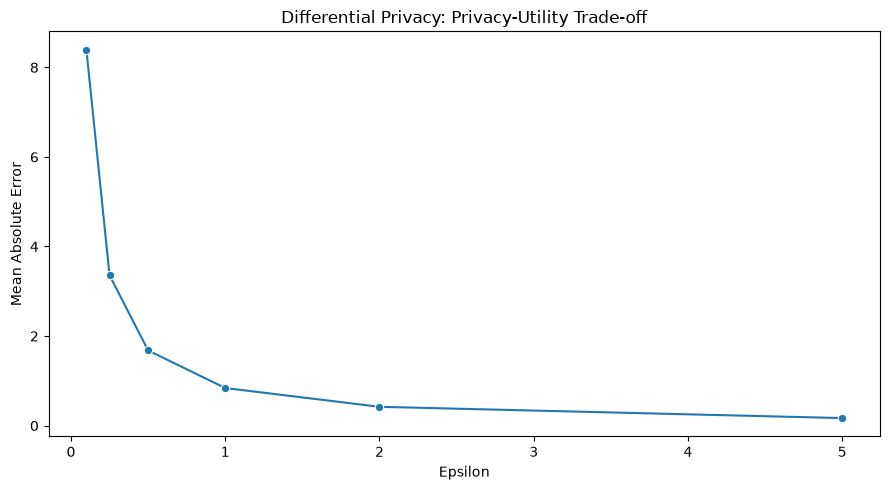

In [13]:
# CELL 13: EPSILON SENSITIVITY ANALYSIS

epsilon_values = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0]

epsilon_results = []

base_counts = dp_demo["unique_subscribers"].to_numpy()

for epsilon in epsilon_values:

    local_rng = np.random.default_rng(RANDOM_STATE)

    noisy_counts = np.array([
        add_laplace_noise(
            value,
            epsilon=epsilon,
            sensitivity=DP_SENSITIVITY,
            rng=local_rng
        )
        for value in base_counts
    ])

    noisy_counts = np.clip(noisy_counts, 0, None)

    mae = np.mean(
        np.abs(noisy_counts - base_counts)
    )

    epsilon_results.append({
        "epsilon": epsilon,
        "mean_absolute_error": mae,
        "noise_scale": DP_SENSITIVITY / epsilon
    })

epsilon_results_df = pd.DataFrame(epsilon_results)

display(epsilon_results_df)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=epsilon_results_df,
    x="epsilon",
    y="mean_absolute_error",
    marker="o"
)

plt.title("Differential Privacy: Privacy-Utility Trade-off")
plt.xlabel("Epsilon")
plt.ylabel("Mean Absolute Error")

plt.tight_layout()
plt.show()

#### 14 — Private Set Intersection: problem definition
Imagine two organisations:
- Operator A: Holds subscriber identifiers and MNO activity.
- Organisation B: Holds a list of identifiers associated with an approved research or service-delivery programme.
The objective is to identify overlapping identifiers without exchanging the original lists.

In a production PSI protocol, the parties use cryptographic techniques such as oblivious pseudorandom functions, commutative encryption or other reviewed PSI constructions.

In [14]:
# CELL 14: PSI - SYNTHETIC PARTIES

operator_a_ids = {
    "SUB001",
    "SUB002",
    "SUB003",
    "SUB004",
    "SUB005",
    "SUB006"
}

organisation_b_ids = {
    "SUB003",
    "SUB004",
    "SUB006",
    "SUB007",
    "SUB008"
}

actual_intersection = operator_a_ids.intersection(
    organisation_b_ids
)

print("Intersection size:", len(actual_intersection))
print("Intersection:", sorted(actual_intersection))

Intersection size: 3
Intersection: ['SUB003', 'SUB004', 'SUB006']


#### 15 — Demonstrate keyed token matching
This cell demonstrates deterministic token matching using HMAC.

Both parties must share the same key for the tokens to match. That key-sharing requirement means this example is not a privacy-preserving PSI protocol.

It is useful only as a functional baseline for understanding how matching works.

In [15]:
# CELL 15: HMAC TOKEN MATCHING - NOT SECURE PSI

shared_demo_key = secrets.token_bytes(32)


def create_matching_token(identifier, key):

    return hmac.new(
        key,
        str(identifier).encode("utf-8"),
        hashlib.sha256
    ).hexdigest()


operator_a_tokens = {
    create_matching_token(x, shared_demo_key)
    for x in operator_a_ids
}

organisation_b_tokens = {
    create_matching_token(x, shared_demo_key)
    for x in organisation_b_ids
}

token_intersection = (
    operator_a_tokens.intersection(
        organisation_b_tokens
    )
)

print("Matching token count:", len(token_intersection))

assert len(token_intersection) == len(actual_intersection)

print("Functional matching test passed.")

Matching token count: 3
Functional matching test passed.


**Security limitation**: The parties share the same key, and the token sets can be linked. A production PSI implementation should use a vetted cryptographic protocol and a clearly defined threat model. Do not use this demonstration to exchange real subscriber identifiers.

#### 16 — PSI implementation design for an operator partnership
This cell documents the proposed production workflow without pretending the cryptographic protocol has been implemented.

In [16]:
# CELL 16: PSI IMPLEMENTATION DESIGN

psi_design = {
    "objective": (
        "Identify approved overlapping records without "
        "exchanging raw subscriber identifiers."
    ),

    "participants": [
        "Mobile Network Operator",
        "Approved Research or Humanitarian Organisation"
    ],

    "inputs": {
        "operator": "Pseudonymous or operator-held subscriber identifiers",
        "partner": "Approved partner-side identifiers"
    },

    "proposed_protocol_requirements": [
        "Use a vetted PSI protocol or reviewed cryptographic library",
        "Define the adversary and collusion model",
        "Authenticate both participants",
        "Use secure transport",
        "Define key and cryptographic parameter management",
        "Limit output to the minimum required intersection result",
        "Apply output disclosure controls",
        "Conduct independent security review"
    ],

    "current_status": (
        "Conceptual design and non-secure functional demonstration only"
    ),

    "not_implemented": [
        "Production PSI protocol",
        "Oblivious pseudorandom function",
        "Cryptographic security review",
        "Operator-to-partner deployment"
    ]
}

with open(
    NOTEBOOK08_DIR / "psi_implementation_design.json",
    "w"
) as f:
    json.dump(psi_design, f, indent=4)

print(json.dumps(psi_design, indent=4))

{
    "objective": "Identify approved overlapping records without exchanging raw subscriber identifiers.",
    "participants": [
        "Mobile Network Operator",
        "Approved Research or Humanitarian Organisation"
    ],
    "inputs": {
        "operator": "Pseudonymous or operator-held subscriber identifiers",
        "partner": "Approved partner-side identifiers"
    },
    "proposed_protocol_requirements": [
        "Use a vetted PSI protocol or reviewed cryptographic library",
        "Define the adversary and collusion model",
        "Authenticate both participants",
        "Use secure transport",
        "Define key and cryptographic parameter management",
        "Limit output to the minimum required intersection result",
        "Apply output disclosure controls",
        "Conduct independent security review"
    ],
    "current_status": "Conceptual design and non-secure functional demonstration only",
    "not_implemented": [
        "Production PSI protocol",
       

#### 17 — Secure Multi-Party Computation: additive secret sharing
MPC allows multiple parties to jointly compute a function without revealing their individual inputs, subject to the security guarantees of the chosen protocol and threat model.

This demonstration uses additive secret sharing over a finite field.

Three parties hold random shares of a value. The shares individually do not reveal the original value under the idealised model, but reconstructing all shares reveals it.

In [17]:
# CELL 17: ADDITIVE SECRET SHARING

PRIME = 2**127 - 1


def create_additive_shares(secret, number_of_parties=3):

    if not 0 <= secret < PRIME:
        raise ValueError(
            "Secret must be within the finite field."
        )

    shares = [
        secrets.randbelow(PRIME)
        for _ in range(number_of_parties - 1)
    ]

    final_share = (
        secret - sum(shares)
    ) % PRIME

    shares.append(final_share)

    return shares


def reconstruct_secret(shares):

    return sum(shares) % PRIME


example_secret = 1250

secret_shares = create_additive_shares(
    example_secret,
    number_of_parties=3
)

print("Party 1 share:", secret_shares[0])
print("Party 2 share:", secret_shares[1])
print("Party 3 share:", secret_shares[2])

reconstructed = reconstruct_secret(secret_shares)

print("Reconstructed value:", reconstructed)

assert reconstructed == example_secret

Party 1 share: 151686495136104518615044902101927096302
Party 2 share: 124652087064951527097869014803519974750
Party 3 share: 63943784719882417750460690526321141652
Reconstructed value: 1250


#### 18 — Demonstrate joint aggregation without revealing individual inputs
Each organisation holds its own subscriber count.

They split the value into random shares and exchange only the shares with the other parties in this simulation.

The shares are combined to recover the total.

In [18]:
# CELL 18: MULTI-PARTY SUM DEMONSTRATION

party_inputs = {
    "MNO_A": 1200,
    "MNO_B": 850,
    "MNO_C": 950
}

number_of_parties = len(party_inputs)

party_shares = {}

for party, value in party_inputs.items():

    party_shares[party] = create_additive_shares(
        value,
        number_of_parties=number_of_parties
    )

# Each receiving party sums the shares it receives.
combined_shares = []

for share_position in range(number_of_parties):

    combined_share = sum(
        party_shares[party][share_position]
        for party in party_inputs
    ) % PRIME

    combined_shares.append(combined_share)

joint_total = reconstruct_secret(combined_shares)

expected_total = sum(party_inputs.values())

print("Jointly computed total:", joint_total)
print("Expected total:", expected_total)

assert joint_total == expected_total

print("MPC arithmetic demonstration passed.")

Jointly computed total: 3000
Expected total: 3000
MPC arithmetic demonstration passed.


**Security limitation**: This is an arithmetic demonstration, not a secure MPC protocol. The shares are collected in one Python process, so there is no real party isolation, secure communication, authenticated execution or malicious-party protection. A production MPC system needs a reviewed protocol and explicit threat model.

#### 19 — Document MPC deployment requirements

In [19]:
# CELL 19: MPC IMPLEMENTATION REQUIREMENTS

mpc_requirements = {
    "objective": (
        "Allow multiple organisations to calculate approved "
        "aggregate statistics without directly sharing raw inputs."
    ),

    "demonstration": "Additive secret sharing",

    "production_requirements": [
        "Define honest-but-curious or malicious adversary model",
        "Define collusion threshold",
        "Use a vetted MPC framework",
        "Establish authenticated communication channels",
        "Protect shares in transit and at rest",
        "Implement party authentication",
        "Define failure and recovery behaviour",
        "Perform independent cryptographic review",
        "Assess computational and communication overhead"
    ],

    "current_status": (
        "Educational additive secret-sharing demonstration only"
    )
}

with open(
    NOTEBOOK08_DIR / "mpc_implementation_requirements.json",
    "w"
) as f:
    json.dump(mpc_requirements, f, indent=4)

print(json.dumps(mpc_requirements, indent=4))

{
    "objective": "Allow multiple organisations to calculate approved aggregate statistics without directly sharing raw inputs.",
    "demonstration": "Additive secret sharing",
    "production_requirements": [
        "Define honest-but-curious or malicious adversary model",
        "Define collusion threshold",
        "Use a vetted MPC framework",
        "Establish authenticated communication channels",
        "Protect shares in transit and at rest",
        "Implement party authentication",
        "Define failure and recovery behaviour",
        "Perform independent cryptographic review",
        "Assess computational and communication overhead"
    ],
    "current_status": "Educational additive secret-sharing demonstration only"
}


#### 20 — Homomorphic Encryption: Paillier setup
Paillier encryption supports additive homomorphic operations.

In particular, encrypted values can be multiplied to obtain an encryption of the sum of the underlying plaintext values, without first decrypting the individual inputs.

In [20]:
# CELL 20: PAILLIER HOMOMORPHIC ENCRYPTION

try:
    from phe import paillier

    HE_AVAILABLE = True

except ImportError:

    HE_AVAILABLE = False

    print(
        "Paillier package unavailable. "
        "Install it using: pip install phe"
    )


if HE_AVAILABLE:

    public_key, private_key = (
        paillier.generate_paillier_keypair(
            n_length=2048
        )
    )

    print("Paillier key pair generated.")

else:

    print("Skipping homomorphic encryption demonstration.")

Paillier key pair generated.


#### 21 — Demonstrate encrypted aggregation

In [21]:
# CELL 21: HOMOMORPHIC ENCRYPTED SUM

if HE_AVAILABLE:

    party_values = [1200, 850, 950]

    encrypted_values = [
        public_key.encrypt(value)
        for value in party_values
    ]

    encrypted_total = encrypted_values[0]

    for encrypted_value in encrypted_values[1:]:

        encrypted_total += encrypted_value

    decrypted_total = private_key.decrypt(
        encrypted_total
    )

    print("Encrypted inputs created.")
    print("Decrypted aggregate total:", decrypted_total)

    assert decrypted_total == sum(party_values)

    print("Homomorphic aggregation demonstration passed.")

Encrypted inputs created.
Decrypted aggregate total: 3000
Homomorphic aggregation demonstration passed.


The individual values are encrypted before aggregation. The private key is required to decrypt the aggregate.

**Security limitation**: This is a small educational example. It does not include a complete distributed key-management system, authenticated participants, secure key custody or a production deployment architecture. Paillier also supports specific arithmetic operations; it is not a general-purpose encrypted database.

#### 22 — Compare privacy approaches

In [22]:
# CELL 22: PRIVACY TECHNOLOGY COMPARISON

privacy_comparison = pd.DataFrame([
    {
        "technique": "Pseudonymisation",
        "primary_purpose": "Reduce direct identifier exposure",
        "raw_data_exchange": "Depends on implementation",
        "key_requirement": "Secret key",
        "current_status": "HMAC demonstration implemented"
    },
    {
        "technique": "Aggregation and suppression",
        "primary_purpose": "Reduce granular output disclosure",
        "raw_data_exchange": "Not inherently prevented",
        "key_requirement": "No cryptographic key required",
        "current_status": "Implemented"
    },
    {
        "technique": "Differential Privacy",
        "primary_purpose": "Bound individual influence on released statistics",
        "raw_data_exchange": "Not inherently prevented",
        "key_requirement": "Privacy budget and controlled randomness",
        "current_status": "Laplace mechanism demonstration implemented"
    },
    {
        "technique": "Private Set Intersection",
        "primary_purpose": "Find common records between parties",
        "raw_data_exchange": "Designed to avoid exchanging raw sets",
        "key_requirement": "Protocol-dependent cryptographic material",
        "current_status": "Conceptual design and insecure matching baseline"
    },
    {
        "technique": "Secure Multi-Party Computation",
        "primary_purpose": "Joint computation over private inputs",
        "raw_data_exchange": "Designed to keep inputs private",
        "key_requirement": "Protocol-dependent",
        "current_status": "Additive sharing demonstration"
    },
    {
        "technique": "Homomorphic Encryption",
        "primary_purpose": "Compute selected functions on encrypted data",
        "raw_data_exchange": "Encrypted inputs can be shared",
        "key_requirement": "Public/private key pair",
        "current_status": "Paillier additive aggregation demonstration"
    }
])

display(privacy_comparison)

,technique,primary_purpose,raw_data_exchange,key_requirement,current_status
0,Pseudonymisation,Reduce direct identifier exposure,Depends on implementation,Secret key,HMAC demonstration implemented
1,Aggregation and suppression,Reduce granular output disclosure,Not inherently prevented,No cryptographic key required,Implemented
2,Differential Privacy,Bound individual influence on released statistics,Not inherently prevented,Privacy budget and controlled randomness,Laplace mechanism demonstration implemented
3,Private Set Intersection,Find common records between parties,Designed to avoid exchanging raw sets,Protocol-dependent cryptographic material,Conceptual design and insecure matching baseline
4,Secure Multi-Party Computation,Joint computation over private inputs,Designed to keep inputs private,Protocol-dependent,Additive sharing demonstration
5,Homomorphic Encryption,Compute selected functions on encrypted data,Encrypted inputs can be shared,Public/private key pair,Paillier additive aggregation demonstration


#### 23 — Create a privacy risk assessment

In [23]:
# CELL 23: PRIVACY RISK ASSESSMENT

privacy_risks = pd.DataFrame([
    {
        "risk": "Subscriber re-identification",
        "potential_impact": "Exposure of subscriber identity",
        "mitigation": "Pseudonymisation, access controls and data minimisation",
        "residual_risk": "Pseudonymised data may remain linkable"
    },
    {
        "risk": "Residential location disclosure",
        "potential_impact": "Exposure of sensitive residential patterns",
        "mitigation": "Spatial aggregation and output review",
        "residual_risk": "Small or unique geographic groups"
    },
    {
        "risk": "Differencing attacks",
        "potential_impact": "Inference of individual contributions",
        "mitigation": "Query controls and differential privacy",
        "residual_risk": "Repeated releases and composition"
    },
    {
        "risk": "Key compromise",
        "potential_impact": "Linkage or recovery of pseudonymous identities",
        "mitigation": "Managed keys, restricted access and rotation",
        "residual_risk": "Compromised key-management infrastructure"
    },
    {
        "risk": "Unauthorised access",
        "potential_impact": "Disclosure of MNO records",
        "mitigation": "Role-based access and audit logging",
        "residual_risk": "Insider threats and misconfiguration"
    },
    {
        "risk": "Insecure multi-party computation",
        "potential_impact": "Exposure of private inputs",
        "mitigation": "Vetted protocols and defined threat models",
        "residual_risk": "Collusion and implementation weaknesses"
    },
    {
        "risk": "Incorrect analytical inference",
        "potential_impact": "Harmful population-level decisions",
        "mitigation": "Validation, uncertainty reporting and human review",
        "residual_risk": "Incomplete or biased network observations"
    }
])

display(privacy_risks)

privacy_risks.to_csv(
    NOTEBOOK08_DIR / "privacy_risk_assessment.csv",
    index=False
)

,risk,potential_impact,mitigation,residual_risk
0,Subscriber re-identification,Exposure of subscriber identity,"Pseudonymisation, access controls and data min...",Pseudonymised data may remain linkable
1,Residential location disclosure,Exposure of sensitive residential patterns,Spatial aggregation and output review,Small or unique geographic groups
2,Differencing attacks,Inference of individual contributions,Query controls and differential privacy,Repeated releases and composition
3,Key compromise,Linkage or recovery of pseudonymous identities,"Managed keys, restricted access and rotation",Compromised key-management infrastructure
4,Unauthorised access,Disclosure of MNO records,Role-based access and audit logging,Insider threats and misconfiguration
5,Insecure multi-party computation,Exposure of private inputs,Vetted protocols and defined threat models,Collusion and implementation weaknesses
6,Incorrect analytical inference,Harmful population-level decisions,"Validation, uncertainty reporting and human re...",Incomplete or biased network observations


#### 24 — Create an operator privacy implementation checklist

In [24]:
# CELL 24: OPERATOR PRIVACY CHECKLIST

privacy_checklist = [
    {
        "area": "Governance",
        "requirement": "Confirm legal basis and permitted processing purpose",
        "status": "Pending"
    },
    {
        "area": "Governance",
        "requirement": "Complete privacy impact assessment",
        "status": "Pending"
    },
    {
        "area": "Data minimisation",
        "requirement": "Document required and excluded fields",
        "status": "Demonstrated"
    },
    {
        "area": "Pseudonymisation",
        "requirement": "Use keyed pseudonymous identifiers",
        "status": "Demonstrated"
    },
    {
        "area": "Key management",
        "requirement": "Implement managed key storage and rotation",
        "status": "Pending"
    },
    {
        "area": "Aggregation",
        "requirement": "Apply geographic aggregation and suppression",
        "status": "Demonstrated"
    },
    {
        "area": "Differential privacy",
        "requirement": "Define privacy budget and contribution bounds",
        "status": "Demonstration only"
    },
    {
        "area": "PSI",
        "requirement": "Select and review a secure PSI protocol",
        "status": "Pending"
    },
    {
        "area": "MPC",
        "requirement": "Define threat model and collusion assumptions",
        "status": "Pending"
    },
    {
        "area": "Homomorphic encryption",
        "requirement": "Review encryption scheme and key custody",
        "status": "Demonstration only"
    },
    {
        "area": "Security",
        "requirement": "Implement access controls and audit logging",
        "status": "Pending"
    },
    {
        "area": "Security",
        "requirement": "Conduct independent security assessment",
        "status": "Pending"
    },
    {
        "area": "Publication",
        "requirement": "Review all released outputs for disclosure risk",
        "status": "Pending"
    }
]

privacy_checklist_df = pd.DataFrame(
    privacy_checklist
)

display(privacy_checklist_df)

privacy_checklist_df.to_csv(
    NOTEBOOK08_DIR / "operator_privacy_checklist.csv",
    index=False
)

,area,requirement,status
0,Governance,Confirm legal basis and permitted processing p...,Pending
1,Governance,Complete privacy impact assessment,Pending
2,Data minimisation,Document required and excluded fields,Demonstrated
3,Pseudonymisation,Use keyed pseudonymous identifiers,Demonstrated
4,Key management,Implement managed key storage and rotation,Pending
5,Aggregation,Apply geographic aggregation and suppression,Demonstrated
6,Differential privacy,Define privacy budget and contribution bounds,Demonstration only
7,PSI,Select and review a secure PSI protocol,Pending
8,MPC,Define threat model and collusion assumptions,Pending
9,Homomorphic encryption,Review encryption scheme and key custody,Demonstration only


#### 25 — Export privacy-safe aggregate results
This exports the aggregate dataset after minimum-group suppression.

The exact subscriber-level intermediate table is deliberately not exported.

In [25]:
# CELL 25: EXPORT PRIVACY-SAFE AGGREGATES

AGGREGATE_OUTPUT = (
    NOTEBOOK08_DIR / "privacy_safe_geographic_aggregates.csv"
)

DP_OUTPUT = (
    NOTEBOOK08_DIR / "differential_privacy_demo_counts.csv"
)

COMPARISON_OUTPUT = (
    NOTEBOOK08_DIR / "privacy_technology_comparison.csv"
)

publishable_aggregates.to_csv(
    AGGREGATE_OUTPUT,
    index=False
)

dp_demo.to_csv(
    DP_OUTPUT,
    index=False
)

privacy_comparison.to_csv(
    COMPARISON_OUTPUT,
    index=False
)

print("Aggregate outputs exported.")
print(AGGREGATE_OUTPUT)
print(DP_OUTPUT)
print(COMPARISON_OUTPUT)

Aggregate outputs exported.
/Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_08/privacy_safe_geographic_aggregates.csv
/Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_08/differential_privacy_demo_counts.csv
/Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_08/privacy_technology_comparison.csv


#### 26 — Generate a privacy implementation summary

In [26]:
# CELL 26: PRIVACY IMPLEMENTATION SUMMARY

privacy_summary = {
    "project": "MNO Mobility Intelligence",

    "notebook": "08_privacy_preserving_mno_analytics",

    "data_source": "Synthetic Kenyan MNO CDR/IPDR data",

    "implemented_demonstrations": [
        "Data minimisation",
        "HMAC-SHA256 pseudonymisation",
        "Key separation demonstration",
        "Chunk-based processing",
        "Geographic aggregation",
        "Minimum-group suppression",
        "Laplace mechanism demonstration",
        "Differential privacy utility analysis",
        "Functional PSI matching baseline",
        "Additive secret sharing",
        "Paillier homomorphic encryption",
        "Privacy risk assessment",
        "Operator privacy checklist"
    ],

    "security_status": {
        "pseudonymisation": "Educational demonstration",
        "differential_privacy": "Illustrative per-zone query",
        "psi": "No secure PSI protocol implemented",
        "mpc": "Educational additive sharing only",
        "homomorphic_encryption": "Educational Paillier example"
    },

    "limitations": [
        "Synthetic data only",
        "No production operator integration",
        "No formal privacy audit",
        "No production PSI protocol",
        "No secure distributed MPC deployment",
        "No production key management",
        "No formal privacy budget for multiple releases"
    ],

    "next_steps": [
        "Define a formal privacy threat model",
        "Implement contribution bounding across releases",
        "Select a vetted PSI protocol",
        "Evaluate a production MPC framework",
        "Review homomorphic encryption parameters",
        "Implement managed key storage",
        "Complete disclosure risk review",
        "Conduct independent security assessment"
    ]
}

SUMMARY_OUTPUT = (
    NOTEBOOK08_DIR / "privacy_implementation_summary.json"
)

with open(SUMMARY_OUTPUT, "w") as f:
    json.dump(privacy_summary, f, indent=4)

print(json.dumps(privacy_summary, indent=4))

{
    "project": "MNO Mobility Intelligence",
    "notebook": "08_privacy_preserving_mno_analytics",
    "data_source": "Synthetic Kenyan MNO CDR/IPDR data",
    "implemented_demonstrations": [
        "Data minimisation",
        "HMAC-SHA256 pseudonymisation",
        "Key separation demonstration",
        "Chunk-based processing",
        "Geographic aggregation",
        "Minimum-group suppression",
        "Laplace mechanism demonstration",
        "Differential privacy utility analysis",
        "Functional PSI matching baseline",
        "Additive secret sharing",
        "Paillier homomorphic encryption",
        "Privacy risk assessment",
        "Operator privacy checklist"
    ],
    "security_status": {
        "pseudonymisation": "Educational demonstration",
        "differential_privacy": "Illustrative per-zone query",
        "psi": "No secure PSI protocol implemented",
        "mpc": "Educational additive sharing only",
        "homomorphic_encryption": "Educational Pa

#### 27 — Close and clean up

In [28]:
# CELL 27: CLEAN UP

# Remove sensitive working objects from the notebook namespace.
# This is not a secure memory wipe; it simply removes references.

for variable_name in [
    "subscriber_zone_records",
    "subscriber_zone_activity",
    "pseudonymised_sample",
    "minimised_sample",
    "sample",
    "minimised_sample",
    "SECRET_KEY_BYTES",
    "secret_key"
]:
    globals().pop(variable_name, None)

print("Notebook 08 processing completed.")
print("Review all outputs before sharing or publishing.")

Notebook 08 processing completed.
Review all outputs before sharing or publishing.
